In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

## Load Experiment

First, we load the experiment from the `results` folder. Each experiment is collected into a single `.parquet` file. Its rows contain recognition results for each configuration (combination) and each fold (flattened).

In [2]:
# Configuration which experiment should be loaded.
EXPERIMENT_NAME = "arcface_against_anonymized_gallery"
RESULTS_PATH = Path("../../results")

In [3]:
# Load the experiment dataset.
EXPERIMENT_PATH = RESULTS_PATH / f"{EXPERIMENT_NAME}.parquet"
EXPERIMENT_DATA = pd.read_parquet(EXPERIMENT_PATH)
EXPERIMENT_DATA

,top-1,top-5,top-10,frame-top-1,fold,gallery_frame_anonymization,gallery_frame_embedding,gallery_frame_aggregation,samples_frame_anonymization,samples_frame_embedding,samples_frame_aggregation,pipeline
0,0.956522,0.972332,0.974967,0.948644,1,none,arcface,video_none,none,arcface,video_none,frame
1,0.966216,0.978041,0.981419,0.958601,2,none,arcface,video_none,none,arcface,video_none,frame
2,0.959335,0.966728,0.968577,0.953381,3,none,arcface,video_none,none,arcface,video_none,frame
3,0.811594,0.906456,0.931489,0.745191,1,none,arcface,video_none,gaussianblur,arcface,video_none,frame
4,0.854730,0.940878,0.954392,0.799595,2,none,arcface,video_none,gaussianblur,arcface,video_none,frame
...,...,...,...,...,...,...,...,...,...,...,...,...
187,0.027027,0.072635,0.108108,0.021700,2,pixelation,arcface,identity_normweighted,blackbar,arcface,video_none,frame
188,0.024030,0.059150,0.094270,0.018951,3,pixelation,arcface,identity_normweighted,blackbar,arcface,video_none,frame
189,0.131752,0.262187,0.324111,0.092721,1,pixelation,arcface,identity_normweighted,pixelation,arcface,video_none,frame
190,0.141892,0.282095,0.359797,0.105573,2,pixelation,arcface,identity_normweighted,pixelation,arcface,video_none,frame


## Visualize accuracy

The following plots show the mean accuracy for each combination of (sample) anonymization method and (gallery) aggregation method. The anonymization method is applied both to the gallery and the samples.

The first plot aggregates the predictions based on their confidence before classifying. The latter does not and instead takes the mean accuracy over all single-frame classifications.

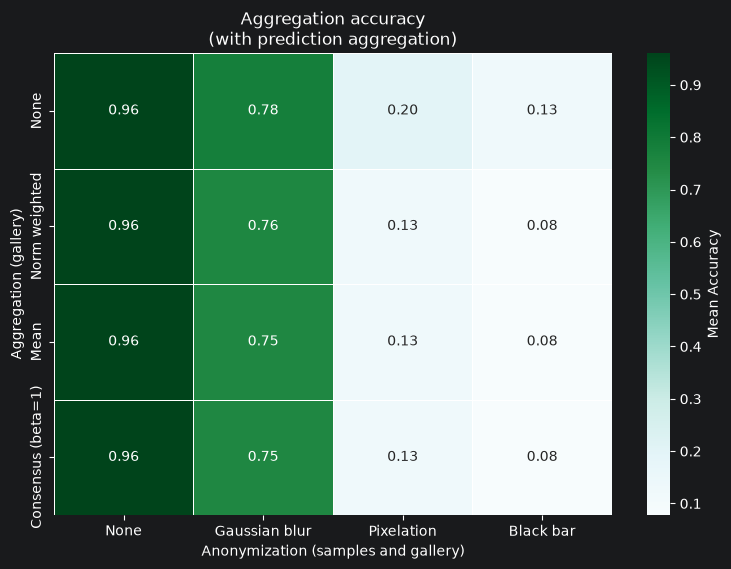

In [28]:
results = EXPERIMENT_DATA[(
        EXPERIMENT_DATA["samples_frame_anonymization"] == EXPERIMENT_DATA["gallery_frame_anonymization"]
)]
results = results.replace({
    "samples_frame_anonymization": {
        "none": "None",
        "gaussianblur": "Gaussian blur",
        "blackbar": "Black bar",
        "pixelation": "Pixelation",
    },
    "gallery_frame_aggregation": {
        "video_none": "None",
        "identity_pooling_mean": "Mean",
        "identity_consensus_beta1": "Consensus (beta=1)",
        "identity_normweighted": "Norm weighted",
    }
})

agg_order = results.groupby("gallery_frame_aggregation")["top-1"].mean().sort_values(ascending=False).index
embedding_order = results.groupby("samples_frame_anonymization")["top-1"].mean().sort_values(ascending=False).index

pivot_agg_embed = results.pivot_table(
    index="gallery_frame_aggregation",
    columns="samples_frame_anonymization",
    values="top-1",
    aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(9, 6))
sns.heatmap(pivot_agg_embed, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Aggregation accuracy\n(with prediction aggregation)")
plt.xlabel("Anonymization (samples and gallery)")
plt.ylabel("Aggregation (gallery)")
plt.show()

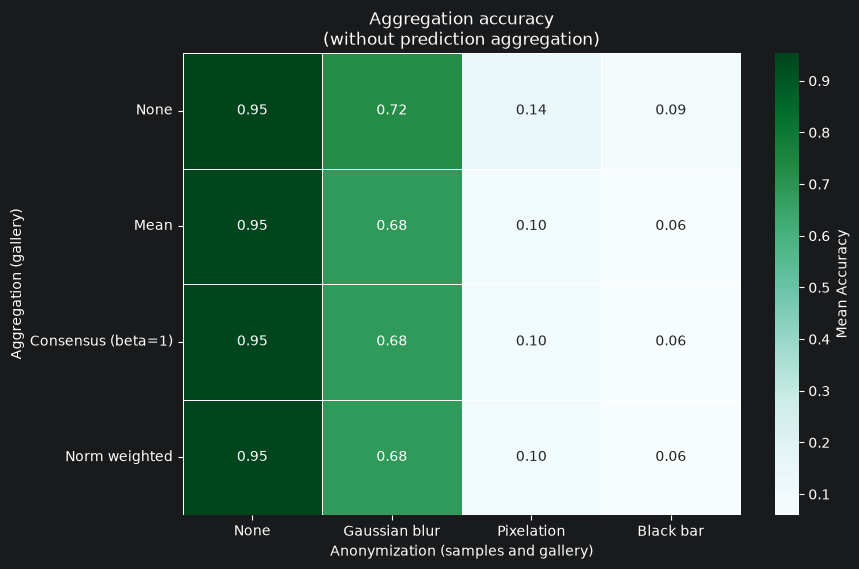

In [29]:
results = EXPERIMENT_DATA[(
        EXPERIMENT_DATA["samples_frame_anonymization"] == EXPERIMENT_DATA["gallery_frame_anonymization"]
)]
results = results.replace({
    "samples_frame_anonymization": {
        "none": "None",
        "gaussianblur": "Gaussian blur",
        "blackbar": "Black bar",
        "pixelation": "Pixelation",
    },
    "gallery_frame_aggregation": {
        "video_none": "None",
        "identity_pooling_mean": "Mean",
        "identity_consensus_beta1": "Consensus (beta=1)",
        "identity_normweighted": "Norm weighted",
    }
})

agg_order = results.groupby("gallery_frame_aggregation")["frame-top-1"].mean().sort_values(ascending=False).index
embedding_order = results.groupby("samples_frame_anonymization")["frame-top-1"].mean().sort_values(ascending=False).index

pivot_agg_embed = results.pivot_table(
    index="gallery_frame_aggregation",
    columns="samples_frame_anonymization",
    values="frame-top-1",
    aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(9, 6))
sns.heatmap(pivot_agg_embed, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Aggregation accuracy\n(without prediction aggregation)")
plt.xlabel("Anonymization (samples and gallery)")
plt.ylabel("Aggregation (gallery)")
plt.show()

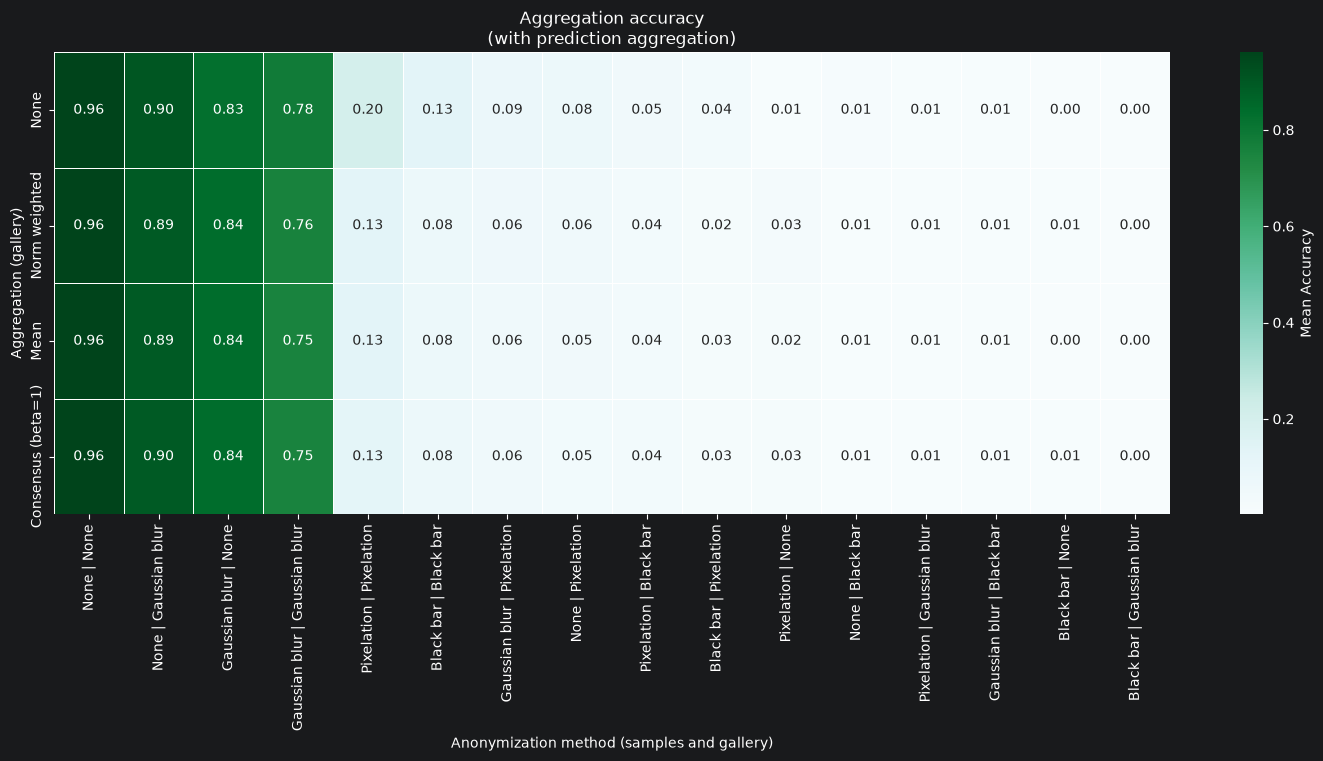

In [18]:
results = EXPERIMENT_DATA.copy()
results = results.replace({
    "samples_frame_anonymization": {
        "none": "None",
        "gaussianblur": "Gaussian blur",
        "blackbar": "Black bar",
        "pixelation": "Pixelation",
    },
    "gallery_frame_anonymization": {
        "none": "None",
        "gaussianblur": "Gaussian blur",
        "blackbar": "Black bar",
        "pixelation": "Pixelation",
    },
    "samples_frame_aggregation": {
        "video_none": "None",
        "identity_pooling_mean": "Mean",
        "identity_consensus_beta1": "Consensus (beta=1)",
        "identity_normweighted": "Norm weighted",
    },
    "gallery_frame_aggregation": {
        "video_none": "None",
        "identity_pooling_mean": "Mean",
        "identity_consensus_beta1": "Consensus (beta=1)",
        "identity_normweighted": "Norm weighted",
    }
})
results = results.assign(
    #frame_aggregation=results["samples_frame_aggregation"] + " | " + results["gallery_frame_aggregation"],
    frame_aggregation=results["gallery_frame_aggregation"],
    frame_anonymization=results["samples_frame_anonymization"] + " | " + results["gallery_frame_anonymization"],
)

agg_order = results.groupby("frame_aggregation")["top-1"].mean().sort_values(ascending=False).index
embedding_order = results.groupby("frame_anonymization")["top-1"].mean().sort_values(ascending=False).index

pivot_agg_embed = results.pivot_table(
    index="frame_aggregation",
    columns="frame_anonymization",
    values="top-1",
    aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(18, 6))
sns.heatmap(pivot_agg_embed, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Aggregation accuracy\n(with prediction aggregation)")
plt.xlabel("Anonymization method (samples and gallery)")
plt.ylabel("Aggregation (gallery)")
plt.show()